# Sales Forecasting: US Monthly Retail Sales

**Goal:** predict how much money US shops will make in the next 12 months.

**Why it matters:** shops use sales forecasts to plan stock, staff and cash. A good forecast means fewer empty shelves and less unsold stock.

**Data:** total US retail sales per month, January 1992 to May 2016 (293 months), in millions of US dollars. Source: US Census Bureau (copy from the Prophet project's examples folder).

**Plan**
1. Load the data and check for missing months
2. Look at the series: trend, seasonality, cycles, noise, outliers
3. Check stationarity (ADF test) and read ACF / PACF charts
4. Split by time: the last 24 months are the test set
5. Build models: naive baselines, AR, ARIMA, exponential smoothing, Holt-Winters, SARIMA, Prophet, Darts
6. Compare them with MAE, RMSE and MAPE
7. Time-series cross-validation to make sure the winner is not lucky
8. Check the winner's errors, then forecast the next 12 months

## 1. Setup

In [1]:
import warnings, logging, itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt, ExponentialSmoothing
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.stats.diagnostic import acorr_ljungbox
from prophet import Prophet
logging.getLogger("darts").setLevel(logging.CRITICAL)   # hide Darts messages about optional extras
from adtk.data import validate_series
from adtk.detector import InterQuartileRangeAD
from darts import TimeSeries
from darts.models import ExponentialSmoothing as DartsExponentialSmoothing
from darts.utils.utils import ModelMode, SeasonalityMode

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").disabled = True   # hide Prophet's progress messages
logging.getLogger("prophet").disabled = True

# simple, clean chart style
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.8,
    "axes.edgecolor": "#8a8984", "axes.titleweight": "bold", "axes.titlesize": 13,
    "lines.linewidth": 2, "font.size": 11,
})
INK = "#0b0b0b"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
IMG = ""
from matplotlib.ticker import StrMethodFormatter
COMMAS = StrMethodFormatter("{x:,.0f}")   # 450000 -> 450,000

Importing plotly failed. Interactive plots will not work.


## 2. Load the data and check the dates

In [2]:
df = pd.read_csv("us_retail_sales.csv", parse_dates=["ds"])
df = df.rename(columns={"ds": "date", "y": "sales"}).set_index("date")
print(df.shape)
df.head()

(293, 1)


,sales
date,
1992-01-01,146376
1992-02-01,147079
1992-03-01,159336
1992-04-01,163669
1992-05-01,170068


In [3]:
df.info()
print("\nFirst month:", df.index.min().date(), " Last month:", df.index.max().date())
print("Missing values:", df["sales"].isna().sum())

<class 'pandas.DataFrame'>
DatetimeIndex: 293 entries, 1992-01-01 to 2016-05-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   sales   293 non-null    int64
dtypes: int64(1)
memory usage: 4.6 KB

First month: 1992-01-01  Last month: 2016-05-01
Missing values: 0


### Are any months missing?

In time series, every time step must be there. A gap (for example, no row for March) breaks the models.

The method from class: build the full list of dates with `pd.date_range`, left join our data onto it, and see which rows come back empty.

In [4]:
full_dates = pd.date_range(start=df.index.min(), end=df.index.max(), freq="MS")   # MS = month start
check = pd.DataFrame(index=full_dates).join(df, how="left")
print("Months expected:", len(full_dates), " Months we have:", len(df))
print("Missing months:", check["sales"].isna().sum())

Months expected: 293  Months we have: 293
Missing months: 0


No months are missing. Good.

**Practice:** to show how we would fix gaps, we remove 3 months from a copy and fill them in three ways.
- `ffill` copies the last known value forward (in the class notes this is `df.fillna(method='ffill')`; new pandas versions use `.ffill()` instead)
- `bfill` copies the next known value backward
- `interpolate` draws a straight line between the neighbours (usually best for sales)

In [5]:
demo = df.copy()
gaps = ["2010-03-01", "2010-04-01", "2012-08-01"]
demo = demo.drop(pd.to_datetime(gaps))

demo = pd.DataFrame(index=pd.date_range(demo.index.min(), demo.index.max(), freq="MS")).join(demo, how="left")
demo["ffill"] = demo["sales"].ffill()
demo["bfill"] = demo["sales"].bfill()
demo["interpolate"] = demo["sales"].interpolate()
compare = demo.loc[pd.to_datetime(gaps), ["ffill", "bfill", "interpolate"]]
compare["real value"] = df.loc[pd.to_datetime(gaps), "sales"]
compare

,ffill,bfill,interpolate,real value
2010-03-01,311022.0,365713.0,329252.333333,360819
2010-04-01,311022.0,365713.0,347482.666667,356460
2012-08-01,396020.0,385597.0,390808.500000,417911


Interpolation lands closest to the real values here. Our real data has no gaps, so we continue with it as it is.

In [6]:
y = df["sales"].asfreq("MS")   # tell pandas the data is monthly

## 3. Look at the series

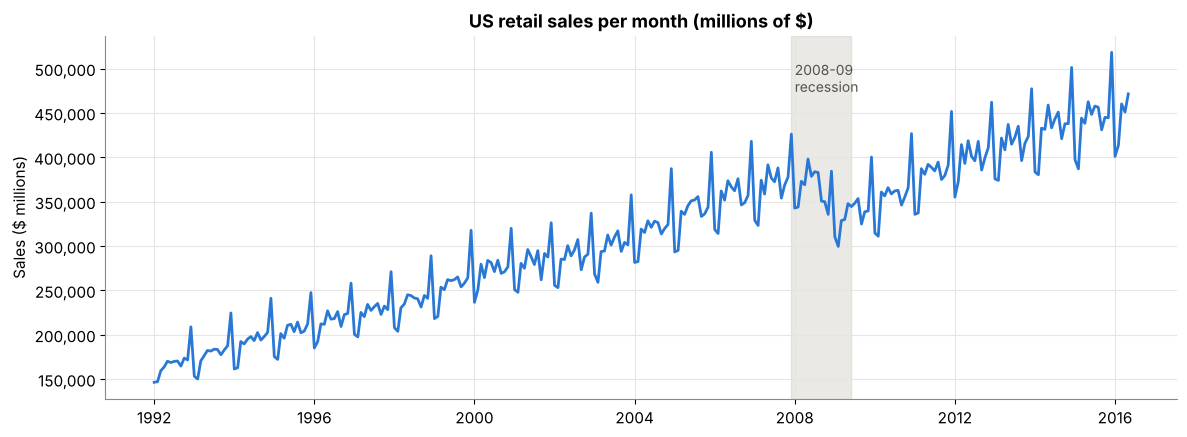

In [7]:
fig, ax = plt.subplots()
ax.plot(y, color=COLORS[0])
ax.axvspan(pd.Timestamp("2007-12-01"), pd.Timestamp("2009-06-01"), color="#c3c2b7", alpha=0.35)
ax.text(pd.Timestamp("2008-01-01"), y.max()*0.98, "2008-09\nrecession", fontsize=10, color="#52514e", va="top")
ax.set_title("US retail sales per month (millions of $)")
ax.set_ylabel("Sales ($ millions)"); ax.yaxis.set_major_formatter(COMMAS)
plt.tight_layout(); plt.savefig(IMG + "01_sales_over_time.png", bbox_inches="tight"); plt.show()

What we see:
- **Trend:** sales go up over the years (about 3 times bigger in 2016 than in 1992).
- **Seasonality:** the same up-and-down pattern repeats every year. December is always the highest.
- **Cyclicity:** a big drop in 2008-2009 (the recession). Cycles are like seasons but with no fixed length.
- **Noise:** small random wiggles that nobody can predict.
- The yearly swings get **bigger as sales grow**. This is called *multiplicative* seasonality. Taking the log of sales makes the swings the same size.

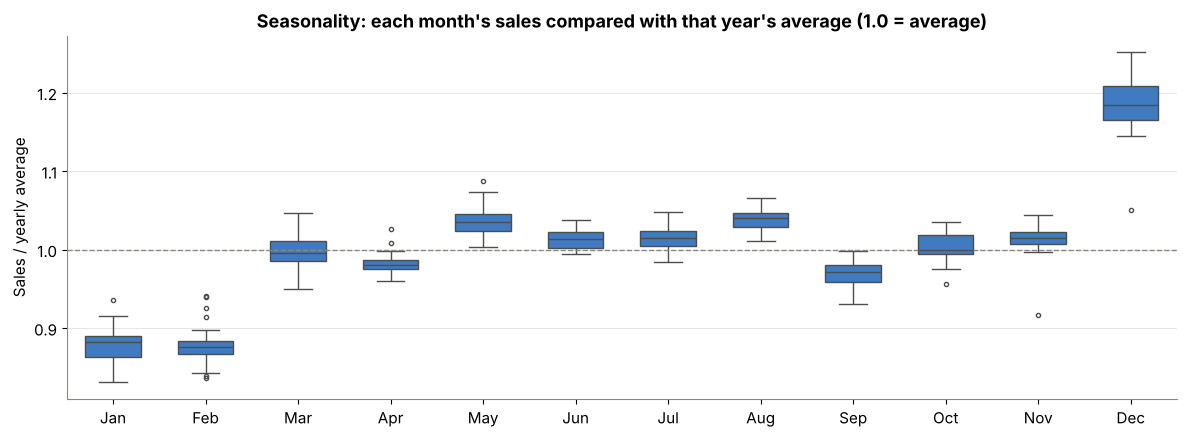

In [8]:
month_df = y.to_frame("sales")
month_df["month"] = month_df.index.month
month_df["year"] = month_df.index.year
month_df["share_of_year"] = month_df["sales"] / month_df.groupby("year")["sales"].transform("mean")

fig, ax = plt.subplots()
sns.boxplot(data=month_df, x="month", y="share_of_year", color=COLORS[0], ax=ax, width=0.6, fliersize=3)
ax.axhline(1, color="#8a8984", lw=1, ls="--")
ax.set_xticks(range(12)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("Seasonality: each month's sales compared with that year's average (1.0 = average)")
ax.set_xlabel(""); ax.set_ylabel("Sales / yearly average")
plt.tight_layout(); plt.savefig(IMG + "02_monthly_pattern.png", bbox_inches="tight"); plt.show()

December is about 15-20% above an average month. January and February are the weakest months.

### Breaking the series into parts (decomposition)

`seasonal_decompose` splits sales into **trend x seasonality x noise** (multiplicative, because the swings grow with sales).

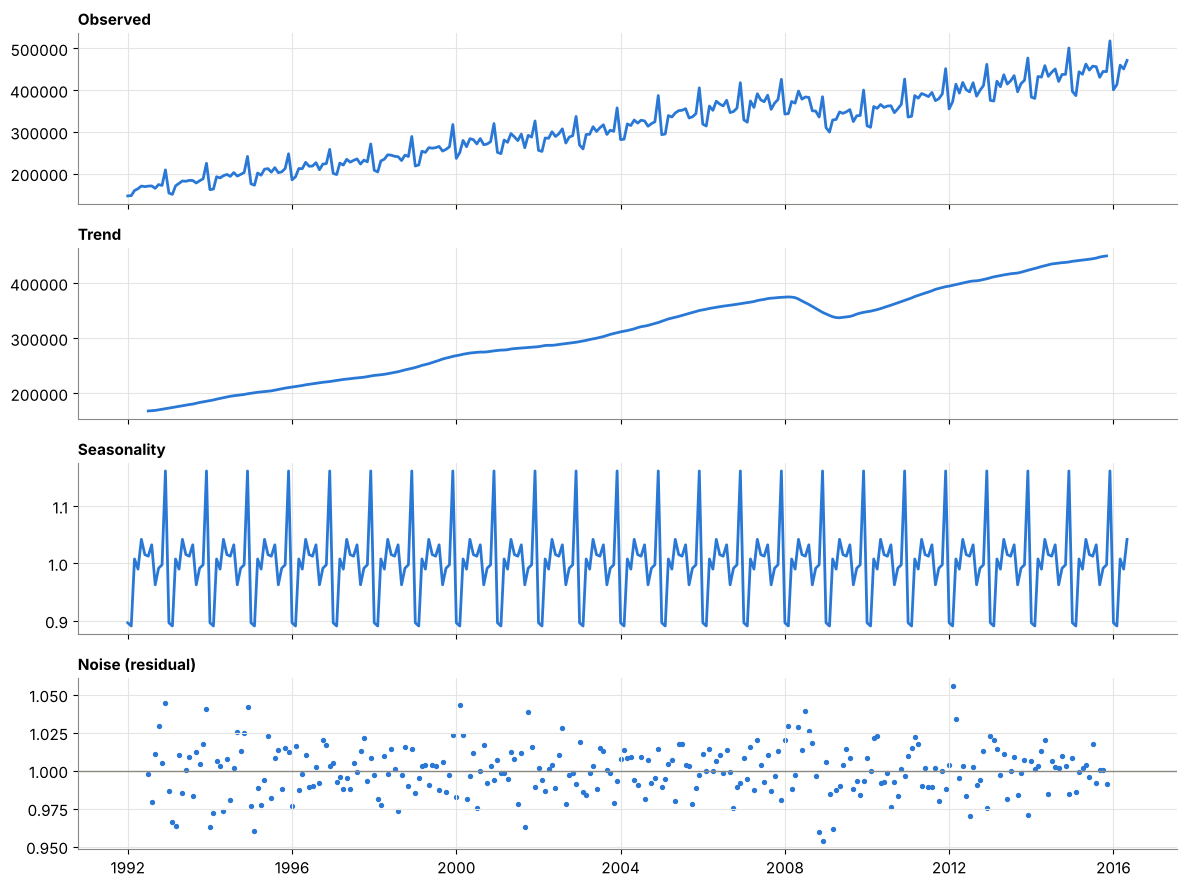

In [9]:
dec = seasonal_decompose(y, model="multiplicative", period=12)
fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
for ax, part, name in zip(axes, [dec.observed, dec.trend, dec.seasonal, dec.resid],
                          ["Observed", "Trend", "Seasonality", "Noise (residual)"]):
    if name.startswith("Noise"):
        ax.scatter(part.index, part, s=8, color=COLORS[0])
        ax.axhline(1, color="#8a8984", lw=1)
    else:
        ax.plot(part, color=COLORS[0])
    ax.set_title(name, fontsize=11, loc="left")
plt.tight_layout(); plt.savefig(IMG + "03_decomposition.png", bbox_inches="tight"); plt.show()

- **Trend** climbs steadily, with a clear dip in 2008-2009 (the cycle).
- **Seasonality** is a fixed shape that repeats every 12 months.
- **Noise** is small, mostly within about 2% (values near 1.0), except around the recession.

### Outliers

An **outlier** is a month that is very different from the normal pattern (for example a sudden spike from a big sale, or a crash).

We can't just look at raw sales, because December is *always* high. So we look at the **noise** part from the decomposition. If the noise for one month is very big, that month is unusual.

Method: the **IQR rule** (same as in earlier projects). A value is an outlier if it is below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR. We do it by hand, and also with the **ADTK** library from the class notes (`InterQuartileRangeAD`), to check both give the same answer.

In [10]:
noise = dec.resid.dropna()

# by hand
q1, q3 = noise.quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
manual_outliers = noise[(noise < low) | (noise > high)]

# with ADTK
adtk_flags = InterQuartileRangeAD(c=1.5).fit_detect(validate_series(noise))
adtk_outliers = noise[adtk_flags == True]

print("Same result from both methods:", manual_outliers.index.equals(adtk_outliers.index))
out_table = pd.DataFrame({"sales": y[manual_outliers.index],
                          "noise (1.0 = normal)": manual_outliers.round(3),
                          "days in month": manual_outliers.index.days_in_month})
out_table

Same result from both methods: True


,sales,noise (1.0 = normal),days in month
date,,,
1992-12-01,208838,1.044,31
2000-02-01,250580,1.043,29
2008-12-01,384286,0.954,31
2012-02-01,372523,1.056,29


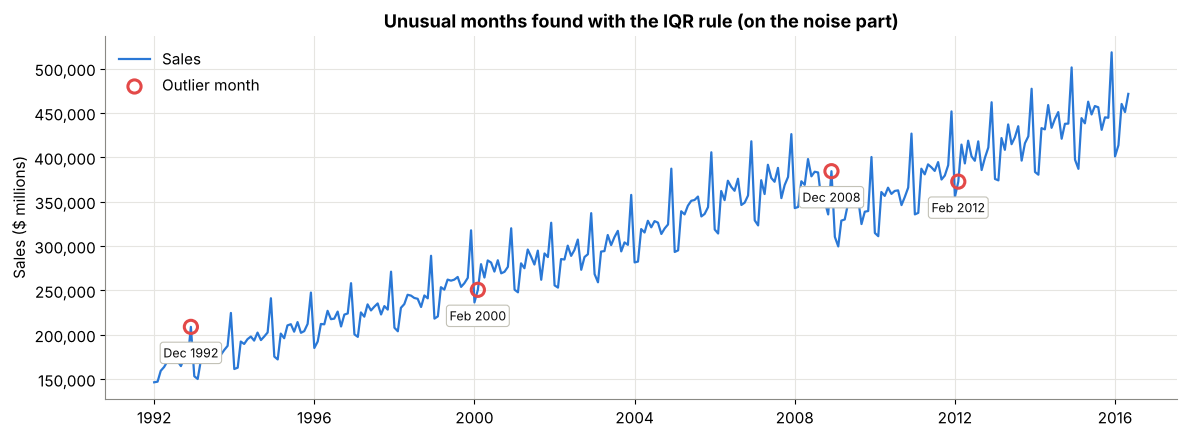

In [11]:
fig, ax = plt.subplots()
ax.plot(y, color=COLORS[0], lw=1.6, label="Sales")
ax.scatter(manual_outliers.index, y[manual_outliers.index], s=90, facecolor="none", edgecolor=COLORS[7], lw=2.2,
           zorder=3, label="Outlier month")
for d in manual_outliers.index:
    ax.annotate(f"{d:%b %Y}", (d, y[d]), xytext=(0, -22), textcoords="offset points", ha="center", fontsize=9, color="#0b0b0b",
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#c3c2b7", lw=0.8))
ax.set_title("Unusual months found with the IQR rule (on the noise part)")
ax.set_ylabel("Sales ($ millions)"); ax.yaxis.set_major_formatter(COMMAS); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(IMG + "03b_outliers.png", bbox_inches="tight"); plt.show()

We found 4 unusual months:
- **Dec 2008:** much lower than a normal December. This is the recession.
- **Feb 2000 and Feb 2012:** higher than a normal February. Both are **leap years**, so February had 29 days instead of 28. One extra shopping day = more sales. (This is a calendar effect, and we will see it again later.)
- **Dec 1992:** a stronger than normal December.

**What do we do with them?** They are real events, not data mistakes, so we **keep** them. Removing a real recession would make the model think recessions never happen. In time series we also can't simply delete a month, because that would create a gap in the dates.

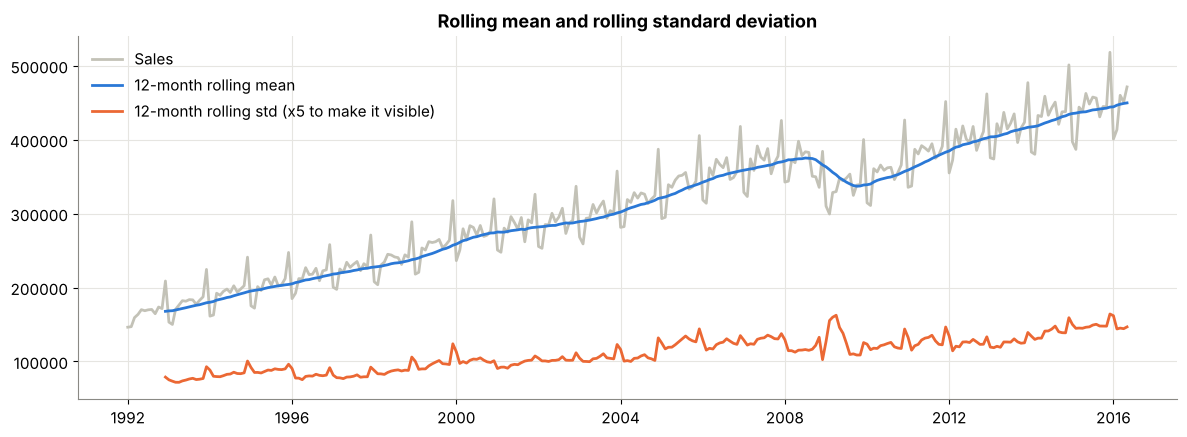

In [12]:
fig, ax = plt.subplots()
ax.plot(y, color="#c3c2b7", label="Sales")
ax.plot(y.rolling(12).mean(), color=COLORS[0], label="12-month rolling mean")
ax.plot(y.rolling(12).std() * 5, color=COLORS[1], label="12-month rolling std (x5 to make it visible)")
ax.set_title("Rolling mean and rolling standard deviation")
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

The average keeps rising and the spread also changes. So the series is **not stationary**. Let's check that with a proper test.

## 4. Stationarity and the ADF test

**Stationary** means the average and the spread stay the same over time. ARIMA-type models need a stationary series.

**ADF test (Augmented Dickey-Fuller):**
- Null hypothesis: the series is *not* stationary.
- If p-value < 0.05, we reject it, so the series **is** stationary.

We try a few changes:
- **log:** makes the seasonal swings the same size
- **difference** (`diff(1)`): this month minus last month, removes the trend
- **seasonal difference** (`diff(12)`): this month minus the same month last year, removes seasonality

Here is what "lag" and "difference" look like (like the small table in the class notes):

In [13]:
lag_demo = y.to_frame("sales").head(14)
lag_demo["lag_1"] = lag_demo["sales"].shift(1)              # last month's sales
lag_demo["D_sales (d=1)"] = lag_demo["sales"].diff(1)       # sales - lag_1
lag_demo["lag_12"] = lag_demo["sales"].shift(12)            # same month last year
lag_demo["seasonal diff (D=1)"] = lag_demo["sales"].diff(12)
lag_demo

,sales,lag_1,D_sales (d=1),lag_12,seasonal diff (D=1)
date,,,,,
1992-01-01,146376,NaN,NaN,NaN,NaN
1992-02-01,147079,146376.0,703.0,NaN,NaN
1992-03-01,159336,147079.0,12257.0,NaN,NaN
1992-04-01,163669,159336.0,4333.0,NaN,NaN
1992-05-01,170068,163669.0,6399.0,NaN,NaN
1992-06-01,168663,170068.0,-1405.0,NaN,NaN
1992-07-01,169890,168663.0,1227.0,NaN,NaN
1992-08-01,170364,169890.0,474.0,NaN,NaN
1992-09-01,164617,170364.0,-5747.0,NaN,NaN


In [14]:
def adf_report(series, name):
    stat, p, *_ = adfuller(series.dropna())
    return {"series": name, "ADF statistic": round(stat, 3), "p-value": round(p, 4),
            "stationary?": "Yes" if p < 0.05 else "No"}

log_y = np.log(y)
adf_table = pd.DataFrame([
    adf_report(y, "Raw sales"),
    adf_report(log_y, "Log sales"),
    adf_report(log_y.diff(), "Log + 1 difference (d=1)"),
    adf_report(log_y.diff().diff(12), "Log + 1 difference + seasonal difference (d=1, D=1)"),
])
adf_table

,series,ADF statistic,p-value,stationary?
0,Raw sales,-0.644,0.8606,No
1,Log sales,-1.657,0.4533,No
2,Log + 1 difference (d=1),-3.124,0.0248,Yes
3,"Log + 1 difference + seasonal difference (d=1,...",-5.567,0.0000,Yes


- Raw sales and log sales are **not** stationary (p-value far above 0.05).
- After one normal difference + one seasonal difference, p-value is about 0, so the series **is stationary**.
- This tells us **d = 1** and **D = 1** for SARIMA.

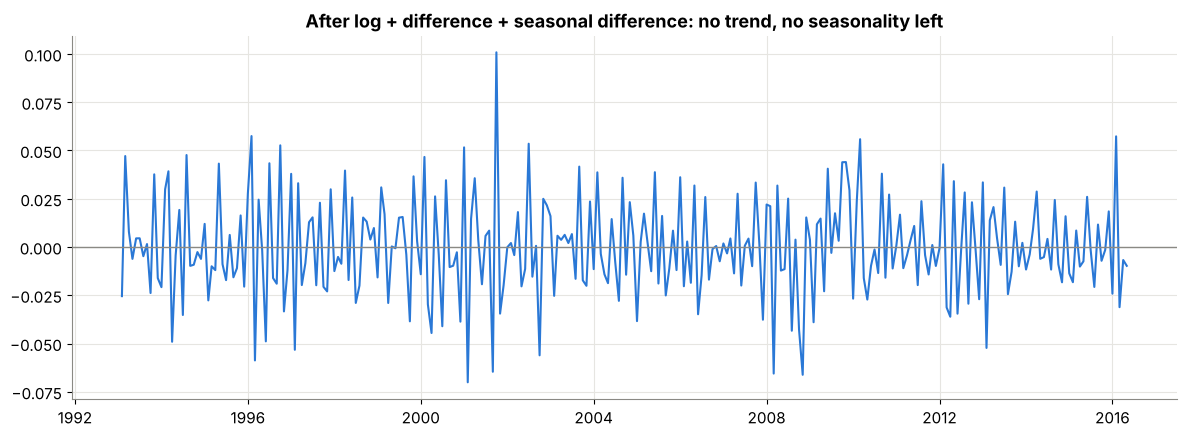

In [15]:
stationary = log_y.diff().diff(12).dropna()
fig, ax = plt.subplots()
ax.plot(stationary, color=COLORS[0], lw=1.5)
ax.axhline(0, color="#8a8984", lw=1)
ax.set_title("After log + difference + seasonal difference: no trend, no seasonality left")
plt.tight_layout(); plt.show()

### ACF and PACF

- **ACF** (autocorrelation): how much this month is related to 1, 2, 3... months ago. Helps choose **q** (MA part).
- **PACF** (partial autocorrelation): the direct link to k months ago, after removing the months in between. Helps choose **p** (AR part).
- Bars outside the blue band are significant.

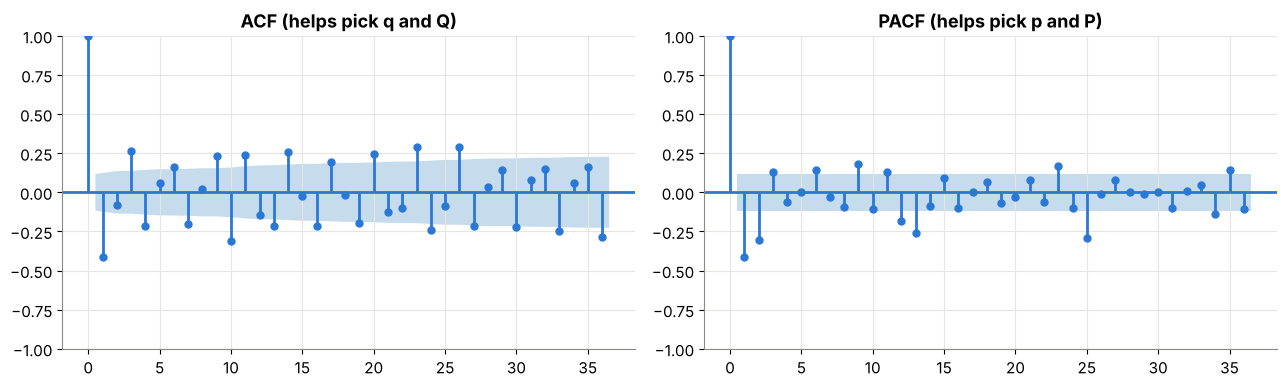

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
plot_acf(stationary, lags=36, ax=axes[0], color=COLORS[0], vlines_kwargs={"colors": COLORS[0]})
plot_pacf(stationary, lags=36, ax=axes[1], method="ywm", color=COLORS[0], vlines_kwargs={"colors": COLORS[0]})
axes[0].set_title("ACF (helps pick q and Q)"); axes[1].set_title("PACF (helps pick p and P)")
plt.tight_layout(); plt.savefig(IMG + "04_acf_pacf.png", bbox_inches="tight"); plt.show()

How to read it:
- Both ACF and PACF have a big spike at **lag 1** and then fade. So small values like **p = 1 or 2** and **q = 1 or 2** make sense.
- The ACF has a negative spike at **lag 12**. That points to a seasonal MA term, **Q = 1**.
- So a good starting guess is SARIMA(1,1,1)(0,1,1,12). Later we also let a small grid search (lowest AIC) pick the final numbers.

## 5. Train / test split (by time, never random)

With time series we must **never shuffle**. The model can only learn from the past and predict the future.

- **Train:** Jan 1992 to May 2014 (269 months)
- **Test:** Jun 2014 to May 2016 (last 24 months)

Train: 1992-01-01 to 2014-05-01 (269 months)
Test:  2014-06-01 to 2016-05-01 (24 months)


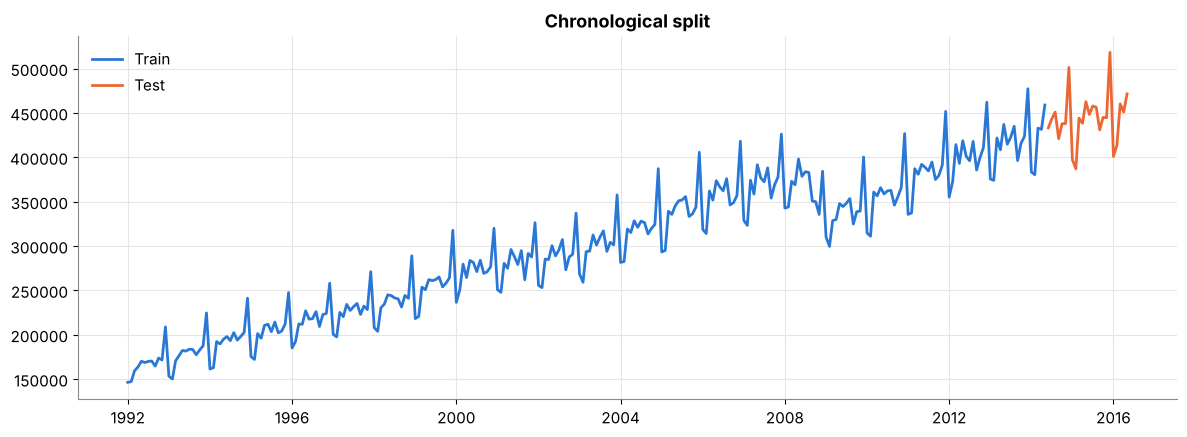

In [17]:
H = 24
train, test = y.iloc[:-H], y.iloc[-H:]
print("Train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} months)")
print("Test: ", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} months)")

fig, ax = plt.subplots()
ax.plot(train, color=COLORS[0], label="Train")
ax.plot(test, color=COLORS[1], label="Test")
ax.set_title("Chronological split"); ax.legend(frameon=False)
plt.tight_layout(); plt.show()

### How we score forecasts

- **MAE** (mean absolute error): on average, how many $ millions we are off. Easy to explain.
- **RMSE** (root mean squared error): like MAE but punishes big misses more.
- **MAPE** (mean absolute percentage error): average error in %. Easy for business people.

Lower is better for all three.

In [18]:
def score(actual, pred, name):
    actual, pred = np.asarray(actual), np.asarray(pred)
    err = actual - pred
    return {"Model": name,
            "MAE": np.mean(np.abs(err)),
            "RMSE": np.sqrt(np.mean(err ** 2)),
            "MAPE %": np.mean(np.abs(err) / actual) * 100}

results, forecasts = [], {}
def record(name, pred):
    pred = pd.Series(np.asarray(pred), index=test.index)
    forecasts[name] = pred
    results.append(score(test, pred, name))
    r = results[-1]
    print(f"{name:32s} MAE={r['MAE']:>9,.0f}  RMSE={r['RMSE']:>9,.0f}  MAPE={r['MAPE %']:.2f}%")

## 6. Models

### 6.1 Naive baselines (the score to beat)

A model is only useful if it beats a simple rule.
- **Naive:** every future month = the last month we saw.
- **Seasonal naive:** every future month = the same month last year.

In [19]:
record("Naive (last value)", np.repeat(train.iloc[-1], H))
record("Seasonal naive (last year)", np.tile(train.iloc[-12:].values, H // 12))

Naive (last value)               MAE=   24,957  RMSE=   32,377  MAPE=5.78%
Seasonal naive (last year)       MAE=   21,197  RMSE=   23,298  MAPE=4.75%


### 6.2 AR (AutoRegressive)

AR predicts this month from the past few months. We fit it on **log sales** with a trend and month effects, then turn the result back with `exp`.

In [20]:
ar = AutoReg(np.log(train), lags=2, trend="ct", seasonal=True, period=12).fit()
ar_pred = np.exp(ar.predict(start=len(train), end=len(train) + H - 1))
record("AR(2) + trend + months", ar_pred)

AR(2) + trend + months           MAE=   14,350  RMSE=   15,515  MAPE=3.21%


### 6.3 ARIMA (no seasonality)

ARIMA(p, d, q) = AR part (p) + differencing (d) + moving-average part (q). We use ARIMA(2,1,2) on log sales. It does **not** know about seasons, so it should do badly here. That is the point: it shows why we need SARIMA.

In [21]:
arima = ARIMA(np.log(train), order=(2, 1, 2)).fit()
record("ARIMA(2,1,2)", np.exp(arima.forecast(H)))

ARIMA(2,1,2)                     MAE=   28,357  RMSE=   34,720  MAPE=6.23%


### 6.4 Exponential smoothing family

These models give **more weight to recent months** and less to old months.
- **Simple Exponential Smoothing:** level only (no trend, no season). Gives a flat line.
- **Holt:** level + trend.
- **Holt-Winters:** level + trend + seasonality. We use *multiplicative* seasonality because the swings grow with sales.
- **Holt-Winters damped:** same, but the trend slowly flattens in the future instead of growing forever. This is often safer for longer forecasts.

In [22]:
ses = SimpleExpSmoothing(train, initialization_method="estimated").fit()
record("Simple Exp. Smoothing", ses.forecast(H))

holt = Holt(train, initialization_method="estimated").fit()
record("Holt (trend)", holt.forecast(H))

hw = ExponentialSmoothing(train, trend="add", seasonal="mul", seasonal_periods=12,
                          initialization_method="estimated").fit()
record("Holt-Winters", hw.forecast(H))

hw_damped = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal="mul",
                                 seasonal_periods=12, initialization_method="estimated").fit()
record("Holt-Winters (damped trend)", hw_damped.forecast(H))

Simple Exp. Smoothing            MAE=   26,681  RMSE=   33,468  MAPE=5.86%


Holt (trend)                     MAE=   19,626  RMSE=   28,288  MAPE=4.44%
Holt-Winters                     MAE=    5,591  RMSE=    7,023  MAPE=1.29%


Holt-Winters (damped trend)      MAE=    4,296  RMSE=    5,580  MAPE=1.00%


### 6.5 SARIMA (ARIMA + seasonality)

SARIMA(p,d,q)(P,D,Q,12) adds a seasonal part that looks back 12, 24... months.

From the ADF test we already know **d = 1, D = 1**. From ACF/PACF our guess was (1,1,1)(0,1,1,12). We also try every small combination and keep the one with the **lowest AIC** (AIC = how well the model fits, with a penalty for being too complex; lower is better).

In [23]:
sarima_guess = SARIMAX(np.log(train), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
record("SARIMA(1,1,1)(0,1,1,12) from ACF/PACF", np.exp(sarima_guess.forecast(H)))


grid = []
for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
    try:
        m = SARIMAX(np.log(train), order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
        grid.append({"order": (p, 1, q), "seasonal_order": (P, 1, Q, 12), "AIC": m.aic})
    except Exception:
        pass
grid = pd.DataFrame(grid).sort_values("AIC").reset_index(drop=True)
grid.head()

SARIMA(1,1,1)(0,1,1,12) from ACF/PACF MAE=    9,335  RMSE=   10,989  MAPE=2.12%


,order,seasonal_order,AIC
0,"(2, 1, 2)","(0, 1, 1, 12)",-1288.443334
1,"(2, 1, 2)","(1, 1, 1, 12)",-1282.293167
2,"(2, 1, 1)","(1, 1, 1, 12)",-1276.997921
3,"(2, 1, 1)","(0, 1, 1, 12)",-1276.719731
4,"(2, 1, 0)","(1, 1, 1, 12)",-1269.275554


In [24]:
best_order, best_seasonal = grid.loc[0, "order"], grid.loc[0, "seasonal_order"]
sarima = SARIMAX(np.log(train), order=best_order, seasonal_order=best_seasonal).fit(disp=False)
record(f"SARIMA{best_order}{best_seasonal[:3]} lowest AIC", np.exp(sarima.forecast(H)))

SARIMA(2, 1, 2)(0, 1, 1) lowest AIC MAE=   15,213  RMSE=   16,641  MAPE=3.43%


### 6.6 Prophet

Prophet is a forecasting tool made by Facebook (Meta). It splits the series into trend + yearly seasonality + holidays, and it is easy to use. It needs two columns named `ds` (date) and `y` (value).

In [25]:
prophet_train = train.reset_index()
prophet_train.columns = ["ds", "y"]
pm = Prophet(seasonality_mode="multiplicative", weekly_seasonality=False, daily_seasonality=False)
pm.fit(prophet_train)
future = pm.make_future_dataframe(periods=H, freq="MS")
prophet_fc = pm.predict(future)
record("Prophet", prophet_fc["yhat"].iloc[-H:].values)

Prophet                          MAE=   12,605  RMSE=   14,370  MAPE=2.83%


### 6.7 Darts library

**Darts** is a forecasting library (mentioned in the class notes) that puts many models behind the same simple `fit()` / `predict()` steps. Here we run its Exponential Smoothing (Holt-Winters) to check that we get the same kind of result as statsmodels.

In [26]:
series = TimeSeries.from_series(y.astype(float))
darts_train, darts_test = series[:-H], series[-H:]

darts_hw = DartsExponentialSmoothing(trend=ModelMode.ADDITIVE, damped=True,
                                     seasonal=SeasonalityMode.MULTIPLICATIVE, seasonal_periods=12)
darts_hw.fit(darts_train)
darts_pred = darts_hw.predict(H)
record("Darts Exp. Smoothing (damped)", darts_pred.values().flatten())

Darts Exp. Smoothing (damped)    MAE=    4,296  RMSE=    5,580  MAPE=1.00%


Darts gives almost the same score as our statsmodels damped Holt-Winters. That makes sense: inside, Darts uses statsmodels for this model. Darts is handy when you want to try many models quickly with the same code.

### 6.8 Blend (average of two models)

Different models make different mistakes. If we average two good models, their mistakes often cancel out a bit. We average **damped Holt-Winters** and our **SARIMA(1,1,1)(0,1,1,12)**. (We did the same trick in the house price project.)

In [27]:
blend_pred = (forecasts["Holt-Winters (damped trend)"] + forecasts["SARIMA(1,1,1)(0,1,1,12) from ACF/PACF"]) / 2
record("Blend: HW damped + SARIMA", blend_pred)

Blend: HW damped + SARIMA        MAE=    6,234  RMSE=    7,603  MAPE=1.43%


## 7. Compare all models on the test set

In [28]:
table = pd.DataFrame(results).sort_values("MAPE %").reset_index(drop=True)
table.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE %": "{:.2f}"}).background_gradient(subset=["MAPE %"], cmap="Blues_r")

,Model,MAE,RMSE,MAPE %
0,Holt-Winters (damped trend),"4,296","5,580",1.00
1,Darts Exp. Smoothing (damped),"4,296","5,580",1.00
2,Holt-Winters,"5,591","7,023",1.29
3,Blend: HW damped + SARIMA,"6,234","7,603",1.43
4,"SARIMA(1,1,1)(0,1,1,12) from ACF/PACF","9,335","10,989",2.12
5,Prophet,"12,605","14,370",2.83
6,AR(2) + trend + months,"14,350","15,515",3.21
7,"SARIMA(2, 1, 2)(0, 1, 1) lowest AIC","15,213","16,641",3.43
8,Holt (trend),"19,626","28,288",4.44
9,Seasonal naive (last year),"21,197","23,298",4.75


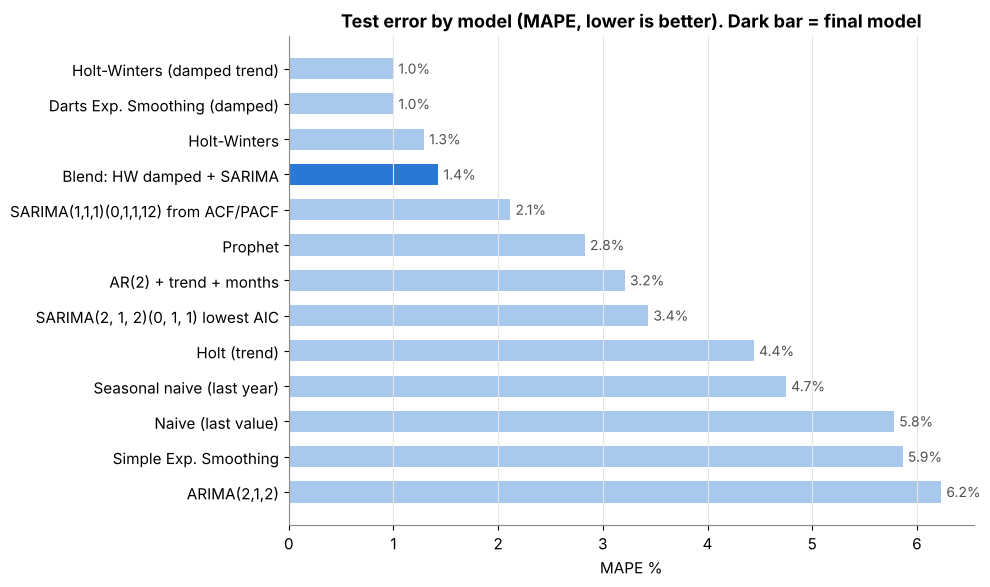

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))
t = table.sort_values("MAPE %", ascending=False)
bar_colors = [COLORS[0] if m.startswith("Blend") else "#a9c8ee" for m in t["Model"]]
ax.barh(t["Model"], t["MAPE %"], color=bar_colors, height=0.6)
for i, v in enumerate(t["MAPE %"]):
    ax.text(v + 0.05, i, f"{v:.1f}%", va="center", fontsize=10, color="#52514e")
ax.set_title("Test error by model (MAPE, lower is better). Dark bar = final model")
ax.set_xlabel("MAPE %"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.savefig(IMG + "05_model_comparison.png", bbox_inches="tight"); plt.show()

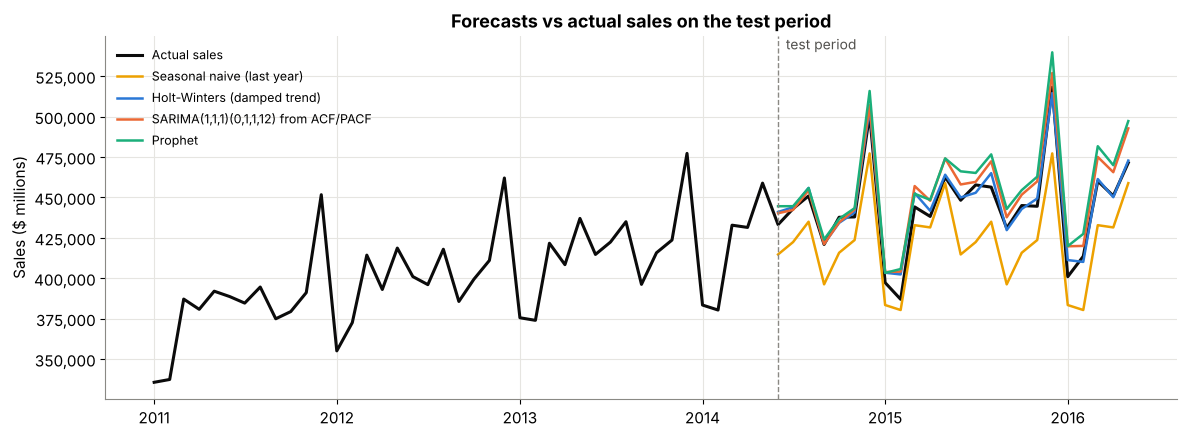

In [30]:
show = ["Seasonal naive (last year)", "Holt-Winters (damped trend)",
        "SARIMA(1,1,1)(0,1,1,12) from ACF/PACF", "Prophet"]
fig, ax = plt.subplots()
ax.plot(y["2011":], color=INK, lw=2.2, label="Actual sales")
for c, name in zip([COLORS[3], COLORS[0], COLORS[1], COLORS[2]], show):
    ax.plot(forecasts[name], color=c, lw=1.8, label=name)
ax.axvline(test.index[0], color="#8a8984", ls="--", lw=1)
ax.text(test.index[0], ax.get_ylim()[1], "  test period", va="top", color="#52514e", fontsize=10)
ax.set_title("Forecasts vs actual sales on the test period")
ax.set_ylabel("Sales ($ millions)"); ax.yaxis.set_major_formatter(COMMAS)
ax.legend(frameon=False, fontsize=9, loc="upper left")
plt.tight_layout(); plt.savefig(IMG + "06_forecasts_vs_actual.png", bbox_inches="tight"); plt.show()

**What happened?**
- Models **without seasonality** (Naive, SES, Holt, ARIMA) do the worst. They cannot see the December peak coming.
- Seasonal naive is already much better. It is a hard baseline to beat.
- **Damped Holt-Winters** wins on this test period (about 1% error). Damping the trend helps because sales growth slowed down in 2015-2016 (low petrol prices pulled retail sales down).
- SARIMA and Prophet catch the seasons well, but they keep the old growth rate going, so they guess a bit too high.
- Surprise: the SARIMA we picked by reading ACF/PACF beat the SARIMA with the **lowest AIC**. AIC measures fit on the past, not forecast skill on the future. A lower AIC does not always mean better forecasts.
- The blend lands between its two parts on this test.

But this is only **one** 2-year period. Is Holt-Winters really the best, or was it lucky? Let's check.

## 8. Time-series cross-validation

One test period can be lucky. So we test again on **5 different years** inside the training data, always training on the past only (an "expanding window").

```
fold 1: train [1992 ......... 2008] -> predict 2009
fold 2: train [1992 ............ 2009] -> predict 2010
...
fold 5: train [1992 .................. 2012] -> predict 2013
```

This is like `TimeSeriesSplit` in scikit-learn. We do it for the strongest models, each forecasting 12 months ahead.

In [31]:
def cv_models(history, h):
    log_h = np.log(history)
    out = {}
    out["Seasonal naive"] = np.tile(history.iloc[-12:].values, h // 12)
    out["Holt-Winters"] = ExponentialSmoothing(history, trend="add", seasonal="mul", seasonal_periods=12,
                                               initialization_method="estimated").fit().forecast(h).values
    out["Holt-Winters (damped)"] = ExponentialSmoothing(history, trend="add", damped_trend=True, seasonal="mul",
                                                        seasonal_periods=12, initialization_method="estimated").fit().forecast(h).values
    out["SARIMA (lowest AIC)"] = np.exp(SARIMAX(log_h, order=best_order, seasonal_order=best_seasonal).fit(disp=False).forecast(h).values)
    out["SARIMA(1,1,1)(0,1,1,12)"] = np.exp(SARIMAX(log_h, order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False).forecast(h).values)
    out["Blend: HW damped + SARIMA"] = (out["Holt-Winters (damped)"] + out["SARIMA(1,1,1)(0,1,1,12)"]) / 2
    p = Prophet(seasonality_mode="multiplicative", weekly_seasonality=False, daily_seasonality=False)
    p.fit(pd.DataFrame({"ds": history.index, "y": history.values}))
    out["Prophet"] = p.predict(p.make_future_dataframe(periods=h, freq="MS"))["yhat"].iloc[-h:].values
    return out

h_cv, n_folds = 12, 5
cv_rows = []
for k in range(n_folds, 0, -1):
    cut = len(train) - k * h_cv
    hist, actual = train.iloc[:cut], train.iloc[cut:cut + h_cv]
    for name, pred in cv_models(hist, h_cv).items():
        row = score(actual, pred, name)
        row["Fold (year predicted)"] = f"{actual.index[0]:%b %Y} - {actual.index[-1]:%b %Y}"
        cv_rows.append(row)
cv = pd.DataFrame(cv_rows)
cv.pivot(index="Fold (year predicted)", columns="Model", values="MAPE %").round(2)

Model,Blend: HW damped + SARIMA,Holt-Winters,Holt-Winters (damped),Prophet,SARIMA (lowest AIC),"SARIMA(1,1,1)(0,1,1,12)",Seasonal naive
Fold (year predicted),,,,,,,
Jun 2009 - May 2010,8.04,13.84,10.96,5.61,5.52,5.13,5.94
Jun 2010 - May 2011,3.36,2.40,3.31,6.20,3.41,3.46,5.71
Jun 2011 - May 2012,2.48,2.11,2.81,9.38,2.28,2.18,6.56
Jun 2012 - May 2013,1.37,1.53,1.72,6.79,0.98,1.18,3.50
Jun 2013 - May 2014,1.21,1.38,1.37,1.17,0.94,1.14,3.55


In [32]:
cv_summary = cv.groupby("Model")[["MAE", "RMSE", "MAPE %"]].mean().sort_values("MAPE %")
cv_summary["MAPE std"] = cv.groupby("Model")["MAPE %"].std()
cv_summary.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "MAPE %": "{:.2f}", "MAPE std": "{:.2f}"})

,MAE,RMSE,MAPE %,MAPE std
Model,,,,
"SARIMA(1,1,1)(0,1,1,12)","9,825","11,896",2.62,1.69
SARIMA (lowest AIC),"9,783","11,615",2.63,1.91
Blend: HW damped + SARIMA,"12,224","14,328",3.29,2.80
Holt-Winters (damped),"14,879","17,122",4.03,3.95
Holt-Winters,"15,498","17,806",4.25,5.38
Seasonal naive,"19,374","20,670",5.05,1.43
Prophet,"22,373","24,093",5.83,2.98


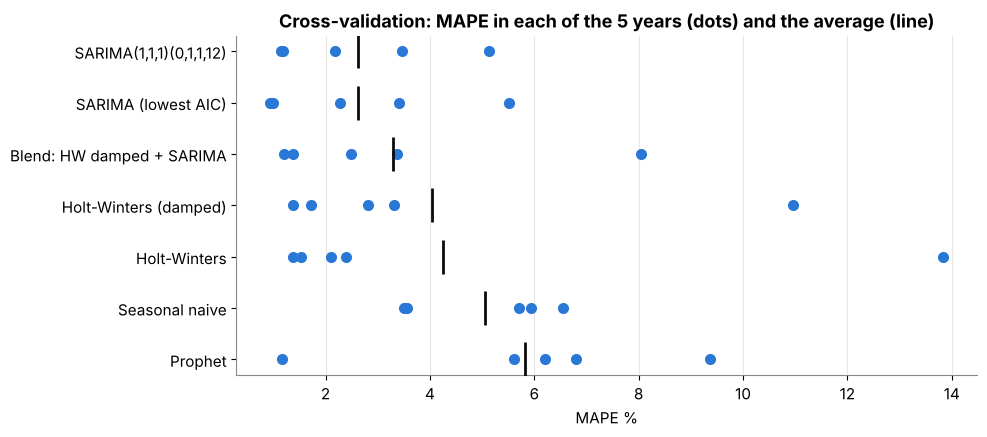

In [33]:
fig, ax = plt.subplots(figsize=(10, 4.5))
order = cv_summary.index.tolist()
sns.stripplot(data=cv, y="Model", x="MAPE %", order=order, color=COLORS[0], size=8, jitter=False, ax=ax)
ax.scatter(cv_summary["MAPE %"], range(len(order)), marker="|", s=600, color=INK, zorder=3)
ax.set_title("Cross-validation: MAPE in each of the 5 years (dots) and the average (line)")
ax.set_ylabel("")
plt.tight_layout(); plt.savefig(IMG + "07_cross_validation.png", bbox_inches="tight"); plt.show()

Cross-validation tells a **different story** from the single test split, and that is exactly why we do it:
- **Holt-Winters** had a very bad year (about 11-14% error for Jun 2009 - May 2010). It learned the steep recession drop as "the trend" and kept pushing sales down while the economy was already recovering.
- **SARIMA** is the most stable model: about 2.6% average error and never a disaster year.
- Prophet struggled in the years after the recession.
- The **blend** is never the best and never the worst. It sits in the middle in every check.

**Which model do we choose?**

| Model | Test MAPE (2014-16) | CV average MAPE (5 years) |
|---|---|---|
| Holt-Winters (damped) | best (~1.0%) | weak (~4.0%, one bad year) |
| SARIMA(1,1,1)(0,1,1,12) | ~2.1% | best (~2.6%) |
| Blend of both | ~1.4% (2nd) | ~3.3% |

No single model wins everywhere. For a real business we want a forecast that is good **and** safe. We choose the **blend** for the final forecast: it was 2nd best on the test period, and averaging protects us when one model goes wrong (like Holt-Winters after 2009).

## 9. Check the final model's errors (residuals)

A good model leaves only random noise behind. We check:
- The errors should look like random noise around 0.
- **Ljung-Box test:** p-value > 0.05 means no pattern is left in the errors (good).

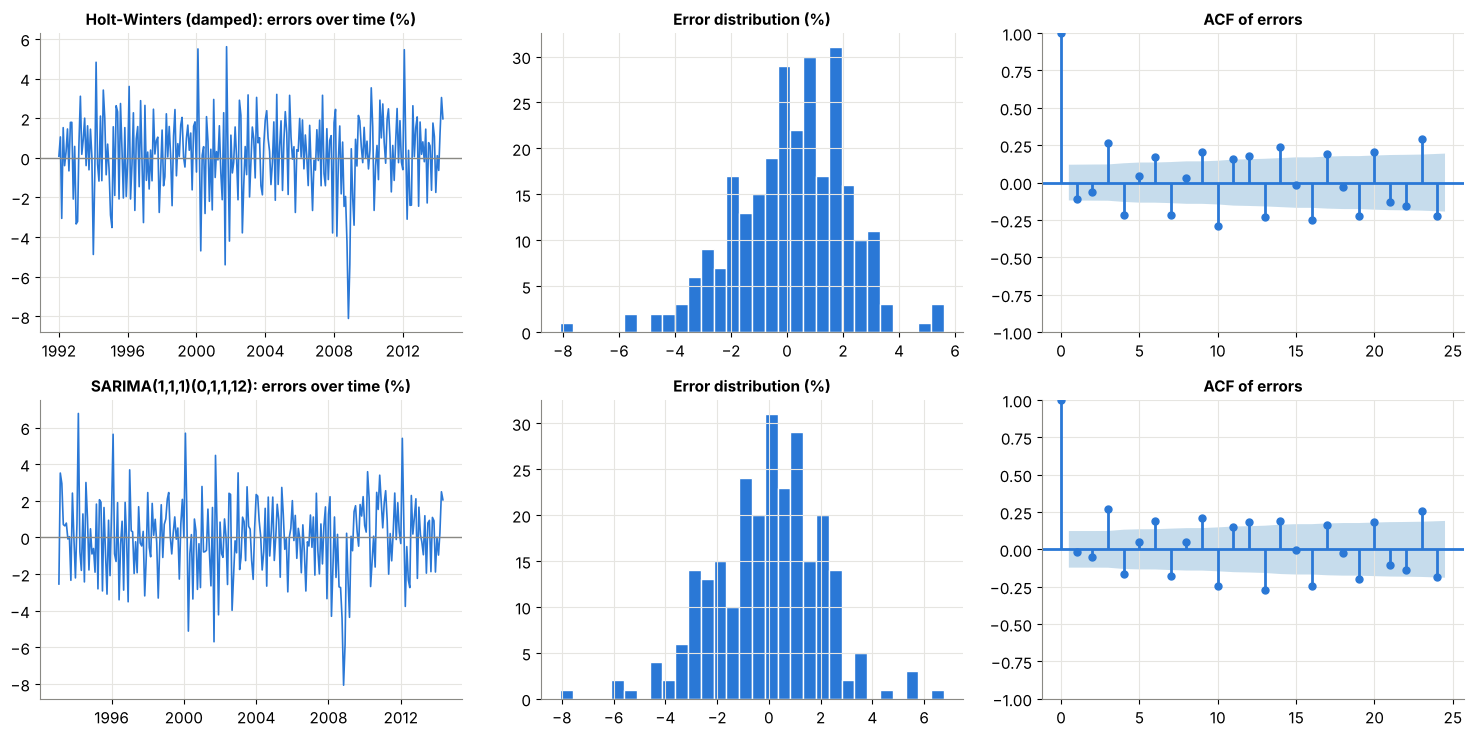

,Model,average error %,error std %,Ljung-Box p-value (12 lags)
0,Holt-Winters (damped),0.15,2.00,1.264598e-17
1,"SARIMA(1,1,1)(0,1,1,12)",-0.04,2.08,9.621442e-14


In [34]:
residuals = {
    "Holt-Winters (damped)": (train - hw_damped.fittedvalues) / train * 100,                       # error in %
    "SARIMA(1,1,1)(0,1,1,12)": (np.log(train) - sarima_guess.fittedvalues).iloc[13:] * 100,   # skip warm-up months
}
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for row, (name, r) in zip(axes, residuals.items()):
    row[0].plot(r, color=COLORS[0], lw=1.2); row[0].axhline(0, color="#8a8984", lw=1)
    row[0].set_title(f"{name}: errors over time (%)", fontsize=11)
    row[1].hist(r, bins=30, color=COLORS[0], edgecolor="white"); row[1].set_title("Error distribution (%)", fontsize=11)
    plot_acf(r.dropna(), lags=24, ax=row[2], color=COLORS[0], vlines_kwargs={"colors": COLORS[0]})
    row[2].set_title("ACF of errors", fontsize=11)
plt.tight_layout(); plt.show()

lb = []
for name, r in residuals.items():
    t = acorr_ljungbox(r.dropna(), lags=[12])
    lb.append({"Model": name, "average error %": round(r.mean(), 2), "error std %": round(r.std(), 2),
               "Ljung-Box p-value (12 lags)": t["lb_pvalue"].iloc[0]})
pd.DataFrame(lb)

- The errors are centred on 0 and are small (about 1-2% for a typical month).
- The biggest errors are in 2008-2009, when the recession surprised everyone. No model can see a recession coming from past sales alone.
- **Honest note:** the Ljung-Box p-values are below 0.05, so a little pattern is still left in the errors. A likely reason is the **calendar**: some months have 5 weekends and some have 4, February has 29 days in leap years (we saw this in the outliers), and Easter moves between March and April. A good next step would be to add "number of weekend days" and "Easter month" as extra inputs (SARIMAX can take extra inputs like this).

## 10. Final forecast: the next 12 months

We retrain both parts of the blend on **all** 293 months and forecast June 2016 to May 2017.

We also want a **range**, not just one number. Both models can give a 95% prediction interval ("we are 95% sure sales will be between these two lines"). For damped Holt-Winters we use `ETSModel`, which is the same idea but can give a range. We average the two ranges as a simple, approximate range for the blend.

In [35]:
future_index = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")

ets_final = ETSModel(y, error="mul", trend="add", damped_trend=True, seasonal="mul",
                     seasonal_periods=12).fit(disp=False)
hw_part = ets_final.get_prediction(start=len(y), end=len(y) + 11).summary_frame(alpha=0.05)
hw_part = hw_part[["mean", "pi_lower", "pi_upper"]].set_axis(["forecast", "low", "high"], axis=1)
hw_part.index = future_index

sarima_final = SARIMAX(np.log(y), order=(1, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
sf = sarima_final.get_forecast(12)
sarima_part = pd.DataFrame({"forecast": np.exp(sf.predicted_mean.values),
                            "low": np.exp(sf.conf_int(alpha=0.05).iloc[:, 0].values),
                            "high": np.exp(sf.conf_int(alpha=0.05).iloc[:, 1].values)}, index=future_index)

future_fc = ((hw_part + sarima_part) / 2).rename(columns={"low": "low (95%)", "high": "high (95%)"})
future_fc["Holt-Winters part"] = hw_part["forecast"]
future_fc["SARIMA part"] = sarima_part["forecast"]
future_fc.round(0).astype(int)

,forecast,low (95%),high (95%),Holt-Winters part,SARIMA part
2016-06-01,456676,437756,474752,455063,458289
2016-07-01,461679,441611,482396,460741,462616
2016-08-01,469562,447142,492290,467901,471223
2016-09-01,437798,415178,461708,436349,439246
2016-10-01,451797,425812,477737,449674,453919
2016-11-01,455405,427585,484842,452289,458522
2016-12-01,523759,488296,559040,519773,527744
2017-01-01,413913,385350,443856,410952,416875
2017-02-01,415617,384948,447490,413170,418064
2017-03-01,468863,434495,506767,465482,472244


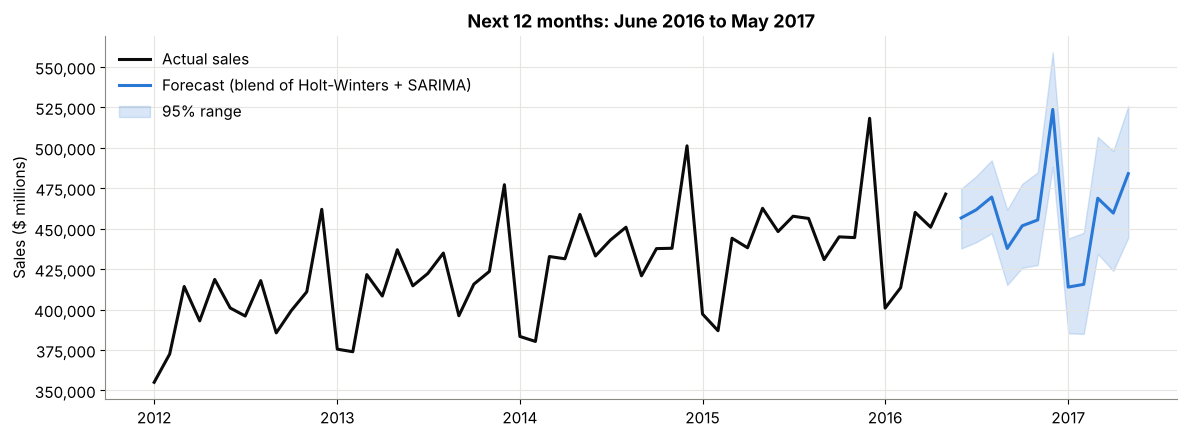

Total forecast for the next 12 months: $5.50 trillion
Same 12 months one year earlier:      $5.40 trillion
Expected growth: 1.9%


In [36]:
fig, ax = plt.subplots()
ax.plot(y["2012":], color=INK, lw=2.2, label="Actual sales")
ax.plot(future_fc["forecast"], color=COLORS[0], lw=2.2, label="Forecast (blend of Holt-Winters + SARIMA)")
ax.fill_between(future_fc.index, future_fc["low (95%)"], future_fc["high (95%)"], color=COLORS[0], alpha=0.18,
                label="95% range")
ax.set_title("Next 12 months: June 2016 to May 2017")
ax.set_ylabel("Sales ($ millions)"); ax.yaxis.set_major_formatter(COMMAS); ax.legend(frameon=False, loc="upper left")
plt.tight_layout(); plt.savefig(IMG + "08_final_forecast.png", bbox_inches="tight"); plt.show()

print(f"Total forecast for the next 12 months: ${future_fc['forecast'].sum()/1e6:,.2f} trillion")
print(f"Same 12 months one year earlier:      ${y.iloc[-12:].sum()/1e6:,.2f} trillion")
print(f"Expected growth: {(future_fc['forecast'].sum()/y.iloc[-12:].sum()-1)*100:.1f}%")

## 11. Summary

**Result:** the final model is a **blend of damped Holt-Winters and SARIMA(1,1,1)(0,1,1,12)**. On the last 24 months it was off by about **1.4% per month** (MAE about $6,000 million on monthly sales of about $440,000 million), much better than the seasonal naive baseline (4.7%). It forecasts about **1.9% growth** for June 2016 - May 2017.

**Key learnings**
1. **Seasonality is everything here.** Every model without seasonality was worse than simply copying last year.
2. **Always build a naive baseline.** Seasonal naive was a strong score to beat and made the other results meaningful.
3. **ADF + ACF/PACF give a good start, AIC search fine-tunes it.** The tests told us d=1 and D=1; the grid search picked p and q.
4. **One test split is not enough.** Holt-Winters looked best on the test, but cross-validation showed it can fail badly after a shock (2009). SARIMA was the most stable.
5. **Lowest AIC is not the same as best forecast.** The SARIMA picked from ACF/PACF beat the SARIMA with the lowest AIC on new data.
6. **Blending two different models is a safe choice.** It was never the best, never the worst.

**Business takeaways**
- December sales are ~15-20% above an average month, and January-February are the weakest. Plan stock and staff around this.
- The forecast is typically off by only 1-3% per month, so it is good enough for stock and budget planning.
- Big shocks (like the 2008 recession) can't be predicted from past sales alone. Watch the 95% range, and retrain the model every month with new data.